# 03. Разведочный анализ данных

## Цель

Изучить состав выборки и распределения свойств белковых последовательностей, сформулировать гипотезы о признаках,полезных для предсказания локализации.


## Импорт библиотек

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

from collections import Counter

import sys
from pathlib import Path

project_root = Path().resolve().parent
sys.path.append(str(project_root))
                
from src.amino_acid_features import calc_sequence_freq, calc_aminoacids_freq, gravy

## Загрузка tsv-файла и проверка структуры данных

In [2]:
df = pd.read_csv("../data/interim/proteins_labeled_candidates.tsv", sep="\t")
df.head(5)

,Entry,Protein names,Length,Sequence,Subcellular location [CC],label
0,A0A096LP01,Small integral membrane protein 26,95,MYRNEFTAWYRRMSVVYGIGTWSVLGSLLYYSRTMAKSSVDQKDGS...,SUBCELLULAR LOCATION: Mitochondrion outer memb...,mitochondrion
1,A0A0B4J2F0,Protein PIGBOS1 (PIGB opposite strand protein 1),54,MFRRLTFAQLLFATVLGIAGGVYIFQPVFEQYAKDQKELKEKMQLV...,SUBCELLULAR LOCATION: Mitochondrion outer memb...,mitochondrion
2,A0A0J9YXV3,Glycine-rich extracellular protein 1 (Long int...,536,MGAWAFPAALFLLCLTSESLQGGLPLLPPGLGKVYGPHSGLGAGYD...,SUBCELLULAR LOCATION: Secreted {ECO:0000269|Pu...,secreted
3,A0A455ZAR2,Transcriptional regulator PINT87aa,87,MLWLPDRGSCSARSPSGMLRGAPGGWRYGRRCGRRRQSCCCCCCCS...,SUBCELLULAR LOCATION: Nucleus {ECO:0000269|Pub...,nucleus
4,A0A494C1I1,Small integral membrane protein 48,119,MADGLFRRRPWGLEQIRPDPESEGLFDKPPPEDPPAARGPRSASAA...,SUBCELLULAR LOCATION: Endoplasmic reticulum me...,endoplasmic_reticulum


In [3]:
print(f"Размер dataframe: {df.shape}")

Размер dataframe: (2545, 6)


In [4]:
print(f"Столбцы текущего dataframe: {list(df.columns)}")

Столбцы текущего dataframe: ['Entry', 'Protein names', 'Length', 'Sequence', 'Subcellular location [CC]', 'label']


In [5]:
print(f"Проверка info:")
df.info()

Проверка info:
<class 'pandas.DataFrame'>
RangeIndex: 2545 entries, 0 to 2544
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Entry                      2545 non-null   str  
 1   Protein names              2545 non-null   str  
 2   Length                     2545 non-null   int64
 3   Sequence                   2545 non-null   str  
 4   Subcellular location [CC]  2545 non-null   str  
 5   label                      2545 non-null   str  
dtypes: int64(1), str(5)
memory usage: 119.4 KB


In [6]:
print(f"Список классов: {list(df["label"].unique())}")

Список классов: ['mitochondrion', 'secreted', 'nucleus', 'endoplasmic_reticulum', 'cell_membrane', 'cytoplasm']


## Подсчёт состава классов

In [7]:
size_classes = df.groupby(by="label").size().sort_values(ascending=True).reset_index(name="size")
size_classes["class_share"] = size_classes["size"] / df.shape[0]
size_classes

,label,size,class_share
0,endoplasmic_reticulum,208,0.081729
1,secreted,258,0.101375
2,mitochondrion,404,0.158743
3,cell_membrane,420,0.165029
4,cytoplasm,520,0.204322
5,nucleus,735,0.288802


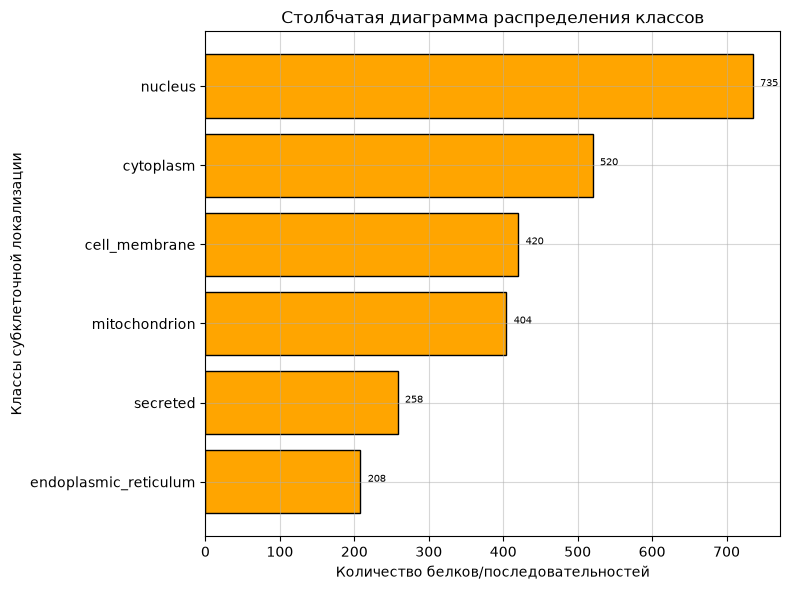

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))

barhs = ax.barh(size_classes["label"], size_classes["size"], color="orange", edgecolor="black")

ax.set_title("Столбчатая диаграмма распределения классов", fontsize=12, loc="center")
ax.set_xlabel("Количество белков/последовательностей")
ax.set_ylabel("Классы субклеточной локализации")

ax.grid(True, alpha=0.5)

for barh, size in zip(barhs,size_classes["size"]):
    ax.text(barh.get_x() + barh.get_width() + 10, barh.get_y() + barh.get_height() / 2, f"{size}", fontsize=7)

plt.tight_layout()
plt.show()

На представленной горизонтальной столбчатой диаграммы представлено распределение классов субклеточной локализации. Самый многочисленный класс: nucleus (ядро), самый малочисленный: endoplasmic_reticulum (ЭПС).
Классы представлены неравномерно. При дальнейшей оценке необходимо смотреть качество по каждому классу, а не только общую долю правильных ответов.

## Общее распределение длин

In [9]:
df["Length"].describe()

count    2545.000000
mean      517.123379
std       468.373719
min        25.000000
25%       249.000000
50%       394.000000
75%       622.000000
max      5654.000000
Name: Length, dtype: float64

In [10]:
label_lenght = df.groupby(by="label")["Length"].agg(
    sum_length="sum",
    max_length="max",
    min_length="min",
    mean_length="mean",
    median_lenght="median"
    ).reset_index()

label_lenght

,label,sum_length,max_length,min_length,mean_length,median_lenght
0,cell_membrane,237112,3258,78,564.552381,429.5
1,cytoplasm,295199,4624,25,567.690385,437.0
2,endoplasmic_reticulum,91775,2754,68,441.225962,375.0
3,mitochondrion,131809,2458,31,326.259901,279.5
4,nucleus,439481,5537,57,597.933333,461.0
5,secreted,120703,5654,64,467.841085,277.5


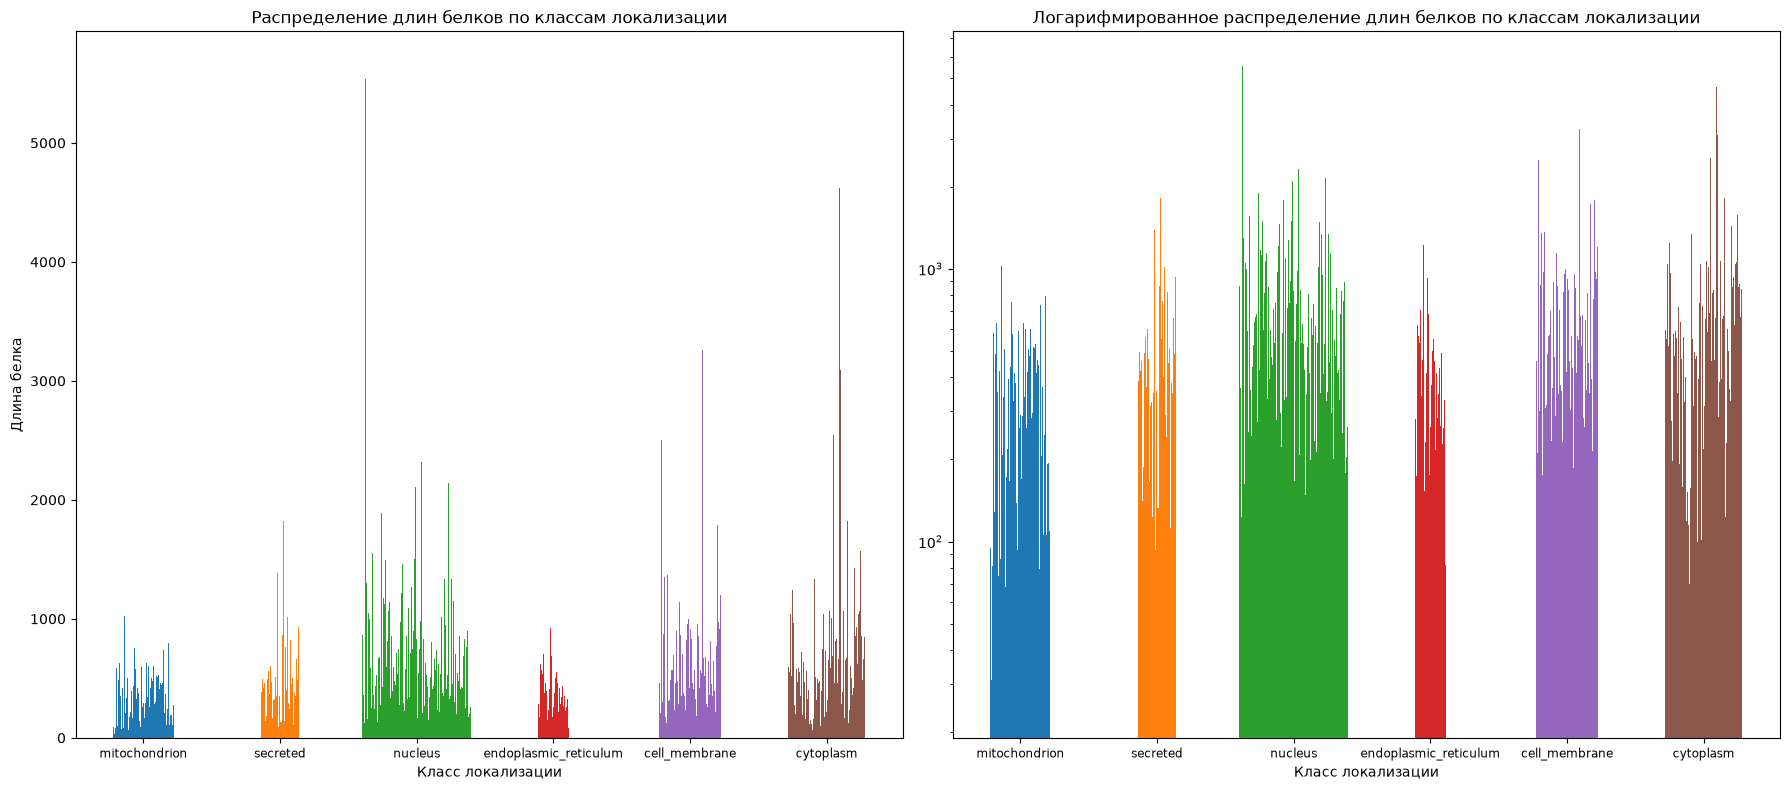

In [11]:
labels = df["label"].unique().tolist()
n_labels = len(labels)

bar_width = 0.8 / df.groupby("label").size().max()

fig, axes = plt.subplots(1, 2,figsize=(18, 8))

for i, label in enumerate(labels):
    lengths = df.loc[df["label"] == label, "Length"].values
    n_bars = len(lengths)

    offsets = (np.arange(n_bars) - (n_bars - 1) / 2) * bar_width
    axes[0].bar(i + offsets, lengths, label=label, width=bar_width * 1.5)
    
    axes[1].bar(i + offsets, lengths, label=label, width=bar_width * 1.5)

axes[0].set_xticks(np.arange(n_labels))
axes[0].set_xticklabels(labels, fontsize=8.5)

axes[0].set_xlabel("Класс локализации")
axes[0].set_ylabel("Длина белка")
axes[0].set_title("Распределение длин белков по классам локализации")

axes[1].set_xticks(np.arange(n_labels))
axes[1].set_xticklabels(labels, fontsize=8.5)

axes[1].set_yscale("log")

axes[1].set_xlabel("Класс локализации")
axes[1].set_title("Логарифмированное распределение длин белков по классам локализации")


plt.tight_layout()
plt.show()

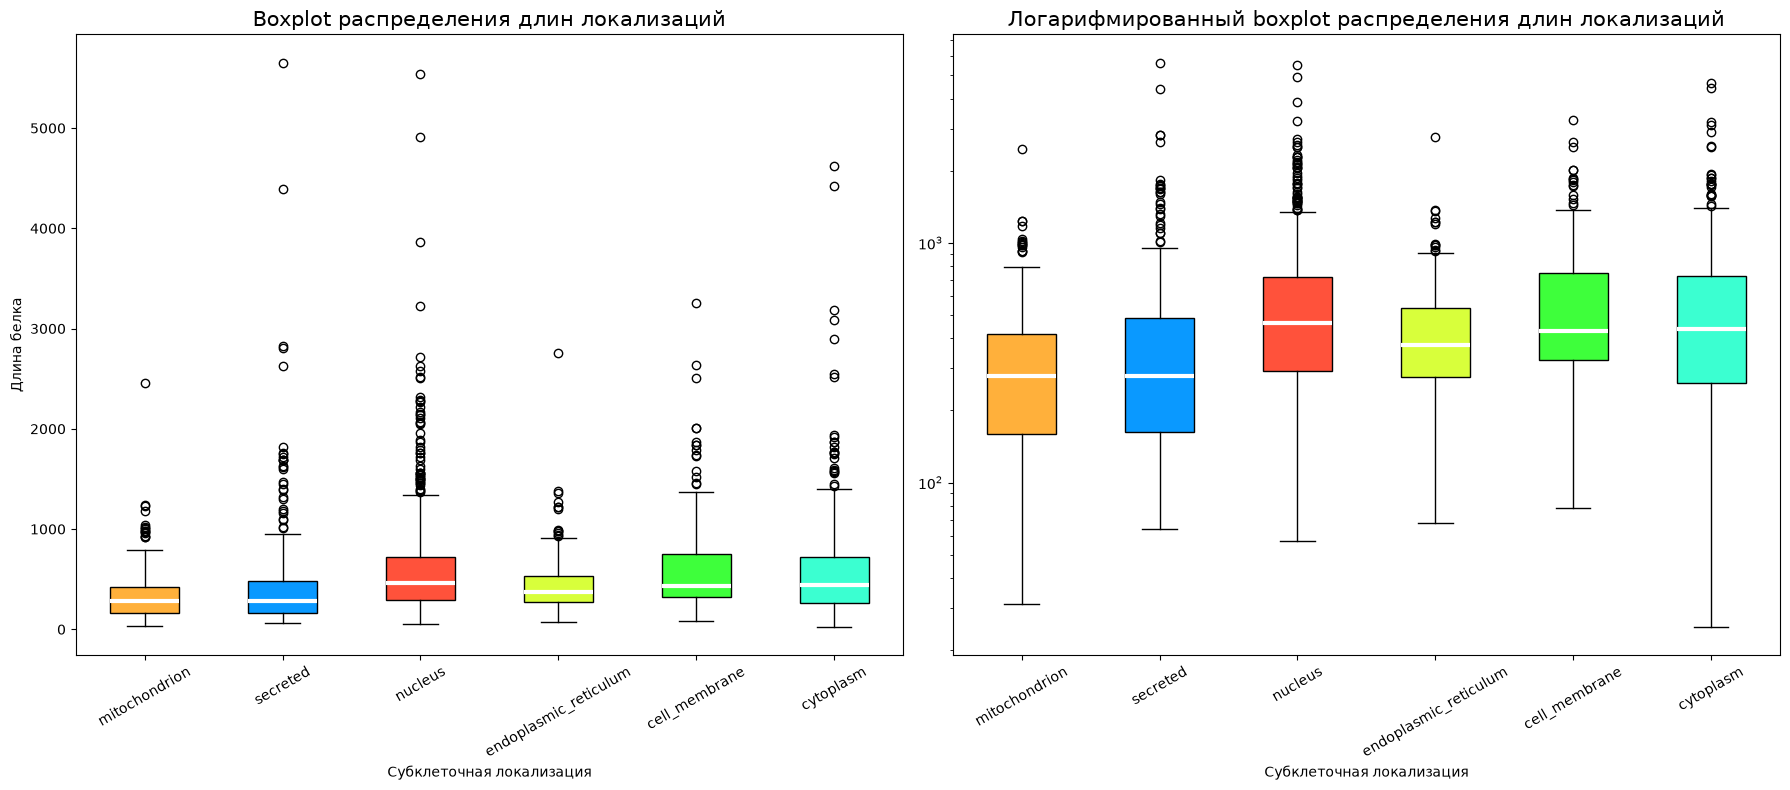

In [12]:
data = [df.loc[df["label"] == label, "Length"].values for label in labels]
colors = ["#ffb03b", "#0a99ff", "#ff523b", "#d8ff3b", "#3eff3b", "#3bffd1"]

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# График нормальный
bp1 = axes[0].boxplot(data, tick_labels=labels, patch_artist=True, medianprops=dict(color="white", lw=3))

axes[0].set_title("Boxplot распределения длин локализаций", fontsize=15)
axes[0].set_xlabel("Субклеточная локализация")
axes[0].set_ylabel("Длина белка")

axes[0].tick_params(axis="x", rotation=30)

# График логарифмированный
bp2 = axes[1].boxplot(data, tick_labels=labels, patch_artist=True, medianprops=dict(color="white", lw=3))

axes[1].set_title("Логарифмированный boxplot распределения длин локализаций", fontsize=15)
axes[1].set_xlabel("Субклеточная локализация")

axes[1].tick_params(axis="x", rotation=30)

axes[1].set_yscale("log")

for bp in [bp1, bp2]:
    for i, color in zip(range(len(bp)), colors):
        bp["boxes"][i].set_facecolor(color)

plt.tight_layout()
plt.show()

Длины белков во всех шести классах распределены с сильным правым скосом: у каждого класса большинство белков короткие, а редкие очень длинные дают выбросы. Значения ниже я снял с графика на глаз, поэтому они приблизительные.

### Основные наблюдения по графику
- Митохондрии имеют самые короткие белки. Медиана около 300 а. о., межквартильный размах примерно 160–420, верхний ус около 800. Это самый компактный и низкий ящик.

- Ядро, клеточная мембрана и цитоплазма имеют самые длинные белки. Медианы у них близки, около 440–470 а. о., а верхний квартиль доходит до 720–750. Усы заканчиваются на 1350–1400.

- Секретируемые белки имеют низкую медиану, около 260 а. о., но самый широкий разброс выбросов. Один белок длиннее 5600 а. о., ещё несколько лежат в диапазоне 2600–4400.

- Эндоплазматический ретикулум занимает промежуточное положение. Медиана около 370 а. о., ящик узкий, усы заканчиваются около 900, выбросы достигают 2750.

На логарифмической шкале видно, что распределения длин белков в разных субклеточных локализациях имеют схожую форму и существенно перекрываются. Медианы лежат в диапазоне примерно 280–470 аминокислотных остатков.

Наиболее короткие белки характерны для митохондрий и секретируемых белков (медианы ~280 а. о.). Наиболее длинные — для ядра (медиана ~470 а. о.). Клеточная мембрана и цитоплазма занимают промежуточное положение (~440 а. о.). Белки эндоплазматического ретикулума имеют наименьший разброс длин.

Из-за значительного перекрытия межквартильных размахов длина белка сама по себе не позволяет надёжно различать локализации и может использоваться только как вспомогательный признак. Логарифмическая шкала делает распределения более симметричными, поэтому при построении модели целесообразно использовать логарифм длины белка.

## Расчёт частот 20 аминокислот

### Расчёт доли аминокислот в последовательностях

In [13]:
freqs = df["Sequence"].apply(calc_sequence_freq)

freq_aa = pd.concat([df[["Entry", "Sequence", "Length"]], freqs], axis=1)
freq_aa

,Entry,Sequence,Length,freq_A,freq_D,freq_E,freq_F,freq_G,freq_I,freq_K,...,freq_P,freq_Q,freq_R,freq_S,freq_T,freq_V,freq_W,freq_Y,freq_C,freq_H
0,A0A096LP01,MYRNEFTAWYRRMSVVYGIGTWSVLGSLLYYSRTMAKSSVDQKDGS...,95,0.031579,0.031579,0.084211,0.031579,0.084211,0.021053,0.063158,...,0.052632,0.010526,0.052632,0.115789,0.084211,0.094737,0.042105,0.084211,0.000000,0.000000
1,A0A0B4J2F0,MFRRLTFAQLLFATVLGIAGGVYIFQPVFEQYAKDQKELKEKMQLV...,54,0.074074,0.018519,0.111111,0.092593,0.055556,0.037037,0.111111,...,0.018519,0.111111,0.037037,0.037037,0.037037,0.074074,0.000000,0.037037,0.000000,0.000000
2,A0A0J9YXV3,MGAWAFPAALFLLCLTSESLQGGLPLLPPGLGKVYGPHSGLGAGYD...,536,0.098881,0.013060,0.027985,0.033582,0.225746,0.005597,0.054104,...,0.134328,0.063433,0.042910,0.026119,0.020522,0.041045,0.014925,0.031716,0.007463,0.016791
3,A0A455ZAR2,MLWLPDRGSCSARSPSGMLRGAPGGWRYGRRCGRRRQSCCCCCCCS...,87,0.057471,0.034483,0.034483,0.011494,0.137931,0.022989,0.034483,...,0.045977,0.022989,0.126437,0.114943,0.000000,0.022989,0.022989,0.022989,0.114943,0.068966
4,A0A494C1I1,MADGLFRRRPWGLEQIRPDPESEGLFDKPPPEDPPAARGPRSASAA...,119,0.142857,0.050420,0.050420,0.050420,0.100840,0.058824,0.050420,...,0.142857,0.033613,0.092437,0.058824,0.016807,0.000000,0.008403,0.025210,0.016807,0.025210
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2540,Q9Y6K8,MNTNDAKEYLARREIPQLFESLLNGLMCSKPEDPVEYLESCLQKVK...,562,0.051601,0.074733,0.088968,0.040925,0.071174,0.071174,0.065836,...,0.049822,0.046263,0.062278,0.064057,0.056940,0.046263,0.003559,0.028470,0.017794,0.007117
2541,Q9Y6N1,MGGLWRPGWRCVPFCGWRWIHPGSPTRAAERVEPFLRPEWSGTGGA...,276,0.083333,0.028986,0.068841,0.054348,0.076087,0.047101,0.043478,...,0.086957,0.039855,0.083333,0.043478,0.054348,0.065217,0.028986,0.039855,0.021739,0.018116
2542,Q9Y6V7,MAGFAELGLSSWLVEQCRQLGLKQPTPVQLGCIPAILEGRDCLGCA...,483,0.082816,0.041408,0.072464,0.039337,0.057971,0.066253,0.076605,...,0.047619,0.062112,0.066253,0.043478,0.057971,0.068323,0.006211,0.014493,0.022774,0.024845
2543,Q9Y6X0,MESRETLSSSRQRGGESDFLPVSSAKPPAAPGCAGEPLLSTPGPGK...,1596,0.061404,0.043233,0.059524,0.021930,0.060777,0.037594,0.104010,...,0.104010,0.040727,0.051378,0.120301,0.056391,0.041980,0.005013,0.018797,0.008145,0.030075


### Расчёт доли аминокислот в метках

In [14]:
freq_label_aa = calc_aminoacids_freq(df)
freq_label_aa

,label,freq_A,freq_D,freq_E,freq_F,freq_G,freq_I,freq_K,freq_L,freq_M,...,freq_P,freq_Q,freq_R,freq_S,freq_T,freq_V,freq_W,freq_Y,freq_C,freq_H
0,cell_membrane,0.070422,0.041466,0.055543,0.047134,0.065125,0.054287,0.044654,0.108894,0.023875,...,0.056109,0.038813,0.051035,0.081915,0.055594,0.067673,0.016351,0.031141,0.027067,0.023179
1,cytoplasm,0.068672,0.051813,0.079587,0.036677,0.060552,0.045346,0.061552,0.103791,0.021907,...,0.055779,0.048249,0.058567,0.076985,0.049692,0.060840,0.011738,0.026206,0.020119,0.025661
2,endoplasmic_reticulum,0.072024,0.041340,0.055473,0.052705,0.065617,0.048761,0.046135,0.123203,0.024211,...,0.053707,0.038976,0.051387,0.070564,0.050972,0.069605,0.019973,0.036426,0.019319,0.027981
3,mitochondrion,0.081269,0.043798,0.064002,0.038305,0.071050,0.046279,0.057341,0.107641,0.024839,...,0.055550,0.044193,0.064950,0.065125,0.049314,0.068311,0.014309,0.028253,0.017806,0.026227
4,nucleus,0.068633,0.049110,0.077186,0.031774,0.065152,0.037883,0.066085,0.087622,0.021819,...,0.073261,0.051317,0.058801,0.089449,0.050603,0.053324,0.008772,0.024481,0.020665,0.028645
5,secreted,0.069857,0.045111,0.056047,0.032675,0.089774,0.034258,0.044945,0.087123,0.017431,...,0.079915,0.044920,0.056933,0.077239,0.064389,0.057770,0.014449,0.026437,0.039668,0.025708


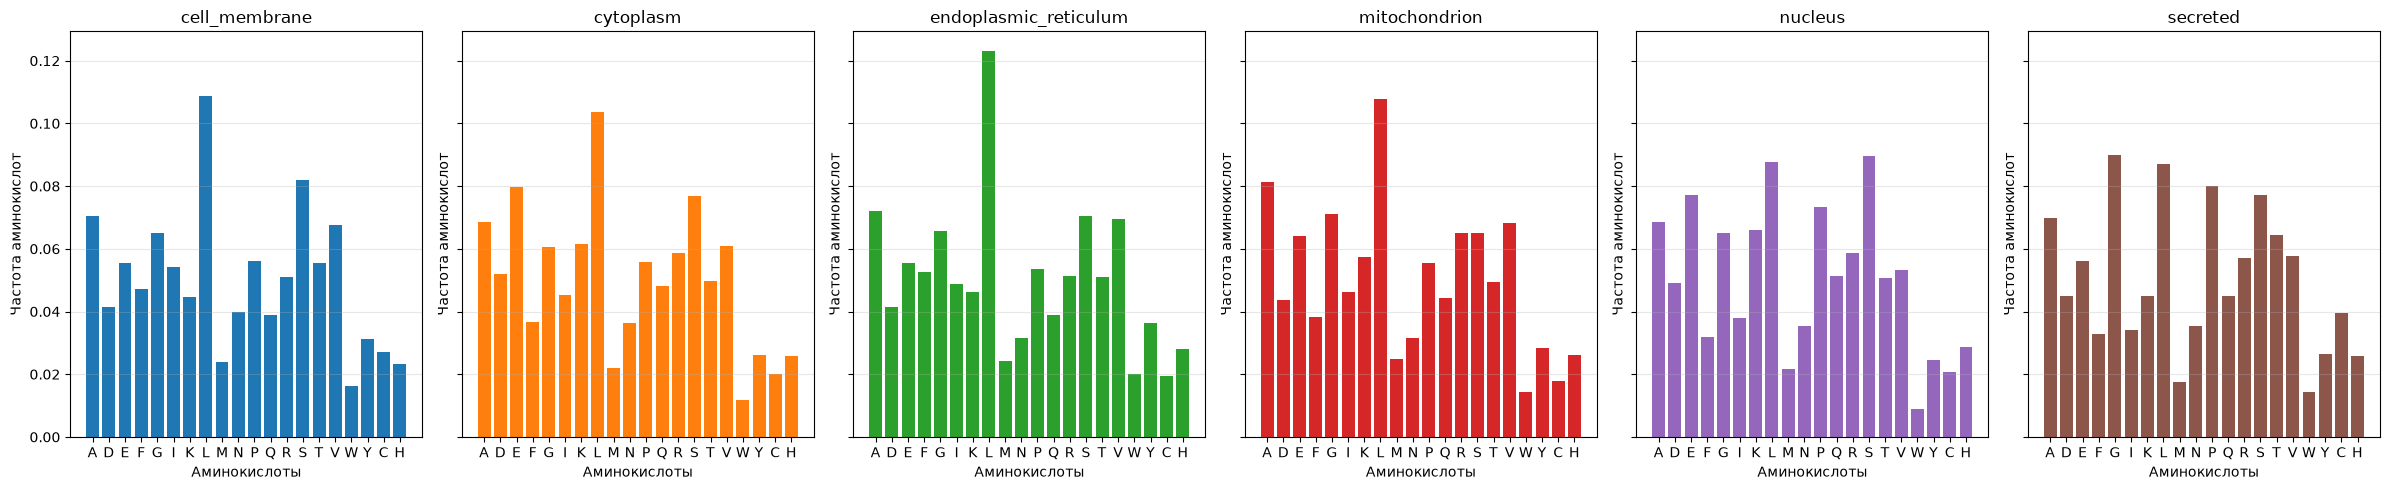

In [15]:
fig, axes = plt.subplots(1, 6, figsize=(24, 5), sharey=True)

for i, ax in enumerate(axes.flatten()):
    ax.bar(freq_label_aa.columns[1:], freq_label_aa.iloc[i, 1:], color=f"C{i}")
    
    ax.set_title(str(freq_label_aa.iloc[i, 0]))
    ax.set_xlabel("Аминокислоты")
    ax.set_ylabel("Частота аминокислот")
    
    ax.set_xticks(range(len(freq_label_aa.columns[1:])))
    ax.set_xticklabels(["A", "D", "E", "F", "G", "I", "K", "L", "M", "N", "P", "Q", "R", "S", "T", "V", "W", "Y", "C", "H"])
    
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Тепловая карта аминокислотного состава

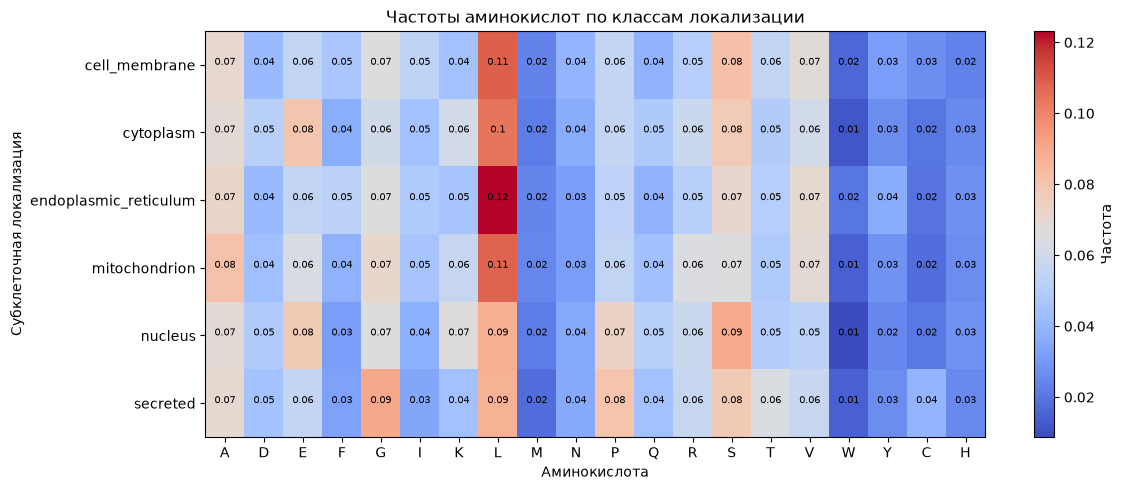

In [16]:
data = freq_label_aa.iloc[:, 1:]

fig, ax = plt.subplots(figsize=(12, 5))

im = ax.imshow(data, cmap="coolwarm", aspect="auto", interpolation="nearest")

for i in range(6):
    for j in range(20):
        val = freq_label_aa.iloc[i, j + 1].round(2)
        ax.text(j, i, f"{val}", fontsize=7, ha="center")

ax.set_xticks(range(data.shape[1]))
ax.set_xticklabels(["A", "D", "E", "F", "G", "I", "K", "L", "M", "N", "P", "Q", "R", "S", "T", "V", "W", "Y", "C", "H"])

ax.set_yticks(range(data.shape[0]))
ax.set_yticklabels(freq_label_aa.iloc[:, 0])

ax.set_xlabel("Аминокислота")
ax.set_ylabel("Субклеточная локализация")
ax.set_title("Частоты аминокислот по классам локализации")

fig.colorbar(im, ax=ax, label="Частота")

plt.tight_layout()
plt.show()

## Простые групповые частоты

Доля K и R:
$$ 𝑓_{𝐾𝑅} = \frac{𝑛_{𝐾} + 𝑛_{𝑅}}{𝐿} $$

Доля D и E:
$$ 𝑓_{DE} = \frac{𝑛_{D} + 𝑛_{E}}{𝐿} $$

In [17]:
# Доля K и R
freq_aa["freq_KR"] = (freq_aa["freq_K"] + freq_aa["freq_R"]) / freq_aa["Length"]
print(f"Средняя доля группы K и R: {freq_aa["freq_KR"].mean()}")

# Доля D и E
freq_aa["freq_DE"] = (freq_aa["freq_D"] + freq_aa["freq_E"]) / freq_aa["Length"]
print(f"Средняя доля группы D и E: {freq_aa["freq_DE"].mean()}")

freq_aa[["Sequence", "Length", "freq_KR", "freq_DE"]]

Средняя доля группы K и R: 0.00043449804371212605
Средняя доля группы D и E: 0.0003618735138865409


,Sequence,Length,freq_KR,freq_DE
0,MYRNEFTAWYRRMSVVYGIGTWSVLGSLLYYSRTMAKSSVDQKDGS...,95,0.001219,0.001219
1,MFRRLTFAQLLFATVLGIAGGVYIFQPVFEQYAKDQKELKEKMQLV...,54,0.002743,0.002401
2,MGAWAFPAALFLLCLTSESLQGGLPLLPPGLGKVYGPHSGLGAGYD...,536,0.000181,0.000077
3,MLWLPDRGSCSARSPSGMLRGAPGGWRYGRRCGRRRQSCCCCCCCS...,87,0.001850,0.000793
4,MADGLFRRRPWGLEQIRPDPESEGLFDKPPPEDPPAARGPRSASAA...,119,0.001200,0.000847
...,...,...,...,...
2540,MNTNDAKEYLARREIPQLFESLLNGLMCSKPEDPVEYLESCLQKVK...,562,0.000228,0.000291
2541,MGGLWRPGWRCVPFCGWRWIHPGSPTRAAERVEPFLRPEWSGTGGA...,276,0.000459,0.000354
2542,MAGFAELGLSSWLVEQCRQLGLKQPTPVQLGCIPAILEGRDCLGCA...,483,0.000296,0.000236
2543,MESRETLSSSRQRGGESDFLPVSSAKPPAAPGCAGEPLLSTPGPGK...,1596,0.000097,0.000064


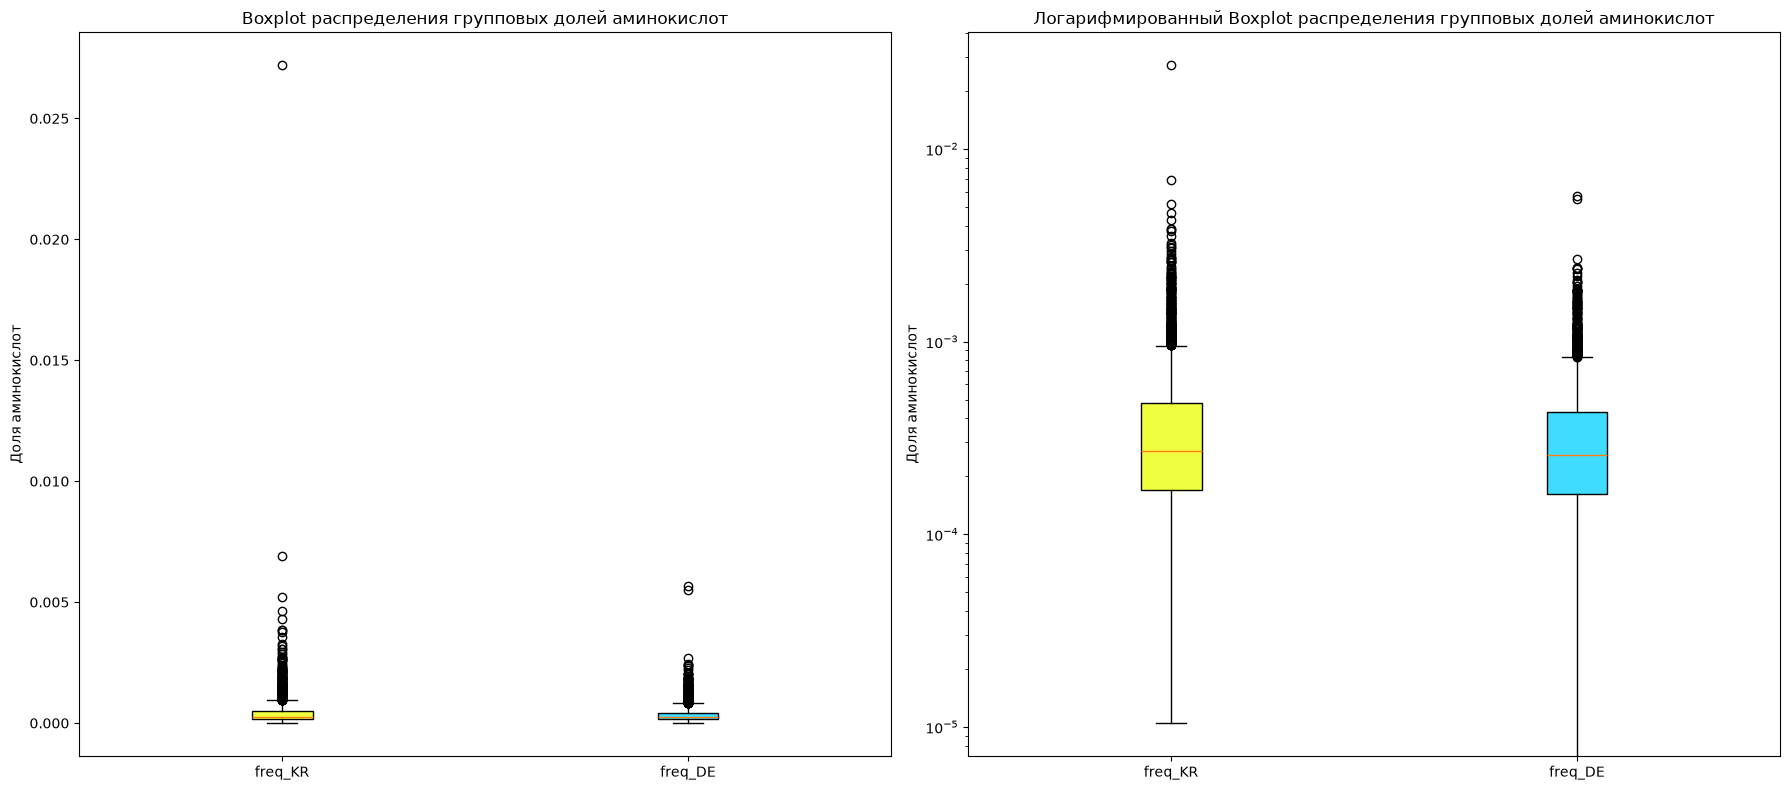

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

bp1 = axes[0].boxplot([freq_aa["freq_KR"], freq_aa["freq_DE"]], patch_artist=True)

axes[0].set_title("Boxplot распределения групповых долей аминокислот")
axes[0].set_xticklabels(labels=["freq_KR", "freq_DE"])

axes[0].set_ylabel("Доля аминокислот")

bp2 = axes[1].boxplot([freq_aa["freq_KR"], freq_aa["freq_DE"]], patch_artist=True)

axes[1].set_title("Логарифмированный Boxplot распределения групповых долей аминокислот")
axes[1].set_xticklabels(labels=["freq_KR", "freq_DE"])

axes[1].set_ylabel("Доля аминокислот")

axes[1].set_yscale("log")

for bp in [bp1, bp2]:
    bp["boxes"][0].set_facecolor("#efff40")
    bp["boxes"][1].set_facecolor("#40dcff")

plt.tight_layout()
plt.show()

По графикам boxplot видно большое количество выбросов по верхней границе. Правый скос показывает смещение в сторону больших значений. Медианы практически на одном уровне (8 * 10e-4), ящики перекрываются перекрываются.

## Средняя гидрофобность

In [23]:
# Для последовательностей
seq_gravy = df["Sequence"].apply(gravy)

In [24]:
# Для меток
label_gravy = df.groupby(by="label")["Sequence"].sum().apply(gravy)
label_gravy

label
cell_membrane           -0.053785
cytoplasm               -0.423678
endoplasmic_reticulum   -0.004825
mitochondrion           -0.245924
nucleus                 -0.616564
secreted                -0.389377
Name: Sequence, dtype: float64